# Проверка гипотезы об активности пользователей книжного приложения

Сравнение времени чтения и прослушивания контента пользователями Москвы и Санкт-Петербурга с помощью одностороннего t-теста Уэлча.


# Часть 1. Проверка гипотезы в Python и составление аналитической записки

Вы предобработали данные в SQL, и теперь они готовы для проверки гипотезы в Python. Загрузите данные пользователей из Москвы и Санкт-Петербурга c суммой часов их активности из файла yandex_knigi_data.csv. Если работаете локально, скачать файл можно по ссылке.

Проверьте наличие дубликатов в идентификаторах пользователей. Сравните размеры групп, их статистики и распределение.

Напомним, как выглядит гипотеза: пользователи из Санкт-Петербурга проводят в среднем больше времени за чтением и прослушиванием книг в приложении, чем пользователи из Москвы. Попробуйте статистически это доказать, используя одностороннюю проверку гипотезы с двумя выборками:

Нулевая гипотеза $H_0: \mu_{\text{СПб}} \leq \mu_{\text{Москва}}$ <br> Среднее время активности пользователей в Санкт-Петербурге не больше, чем в Москве.

Альтернативная гипотеза $H_1: \mu_{\text{СПб}} > \mu_{\text{Москва}}$ <br> Среднее время активности пользователей в Санкт-Петербурге больше, и это различие статистически значимо.

По результатам анализа данных подготовьте аналитическую записку, в которой опишите:

Выбранный тип t-теста и уровень статистической значимости.

Результат теста, или p-value.

Вывод на основе полученного p-value, то есть интерпретацию результатов.

Одну или две возможные причины, объясняющие полученные результаты.

## Напишите заголовок первой части проекта здесь

- Автор: Игнатьев Вячеслав
- Дата: 20.01.2026

## Цели и задачи проекта

<font color='#777778'>В этом блоке перечислите цель проекта и те задачи, которые вы решаете. Можно использовать описания проекта, но будет полезно, если вы сформулируете основную цель проекта самостоятельно.</font>

Для проекта `yandex_knigi_data.csv` целью является проверить гипотезу о том, что пользователи с Санкт-Петербурга больше вовлечены в контент, чем пользователи из Москвы. В качестве ключевой метрики выбираем среднее время активности.

1. Загрузить и обработать данные пользователей:
    1. Проверить дубликаты 
    2. Cравнить выборки (размеры, статистики, распределение)
2. Подготовить дизайн эксперимента и провести расчеты
3. Сформировать аналитическую записку по результатам

## Описание данных

<font color='#777778'>Здесь приведите описание данных.</font>

Таблица `yandex_knigi_data.csv` содержит данные пользователей из Мск и Спб с их активностью.

Поля таблицы:

- `city` — город пользователя;
- `puid` — идентификатор пользователя;
- `hours` — количество часов чтения или просмотра контента;

## Содержимое проекта

<font color='#777778'>Перечислите основные шаги проекта или напишите оглавление. Используйте описание проекта, чтобы зафиксировать основные шаги.</font>

1. Загрузка данных и знакомство с ними
2. Проверка гипотезы в Python
3. Аналитическая записка по результатам

---

## 1. Загрузка данных и знакомство с ними

Загрузите данные пользователей из Москвы и Санкт-Петербурга c их активностью (суммой часов чтения и прослушивания) из файла `/datasets/yandex_knigi_data.csv`.

In [ ]:
# Пустые ячейки после каждого задания — примерное пространство для работы.
# Вы можете свободно добавлять или удалять ячейки по своему усмотрению в зависимости от логики и объёма работы.

In [ ]:
# Используйте ячейки типа Code для вашего кода

In [3]:
#Импортируем библиотеку
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns 

!pip install jupyter-black
import jupyter_black
jupyter_black.load()

     |████████████████████████████████| 1.7 MB 2.1 MB/s eta 0:00:01
     |████████████████████████████████| 74 kB 1.5 MB/s  eta 0:00:01
     |████████████████████████████████| 259 kB 54.8 MB/s eta 0:00:01
     |████████████████████████████████| 55 kB 916 kB/s  eta 0:00:01
  Attempting uninstall: packaging
    Found existing installation: packaging 21.3
    Uninstalling packaging-21.3:
      Successfully uninstalled packaging-21.3


In [4]:
df = pd.read_csv(
    "https://code.s3.yandex.net/datasets/yandex_knigi_data.csv", index_col=0
)
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 8784 entries, 0 to 8783
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   city    8784 non-null   object 
 1   puid    8784 non-null   int64  
 2   hours   8784 non-null   float64
dtypes: float64(1), int64(1), object(1)
memory usage: 274.5+ KB


,city,puid,hours
0,Москва,9668,26.167776
1,Москва,16598,82.111217
2,Москва,80401,4.656906
3,Москва,140205,1.840556
4,Москва,248755,151.326434


Датасет содержит 8784 значений без пропусков. 
Тип данных в столбцах выбран корректно.

In [5]:
# Проверим явные дубликаты
all_dub = df.duplicated().sum()
print(f"Всего полных дубликатов = {all_dub}")
# Проверим неявные дубликаты
puid_dub = df["puid"].duplicated().sum()
print(f"Дубликаты в поле puid = {puid_dub}")

Всего полных дубликатов = 0
Дубликаты в поле puid = 244


In [6]:
# Сохраняем id дублирующихся пользователей
puid = df[df.duplicated(subset=["puid"])]["puid"].to_list()
df[df["puid"].isin(puid)].sort_values(by=["puid", "hours"]).tail(10)

,city,puid,hours
8771,Санкт-Петербург,1130000018516717,0.517778
6190,Москва,1130000018516717,8.073889
6192,Москва,1130000018954257,3.389335
8772,Санкт-Петербург,1130000018954257,33.583294
6195,Москва,1130000020425037,0.310556
8773,Санкт-Петербург,1130000020425037,2.386944
8775,Санкт-Петербург,1130000023864516,14.384722
6202,Москва,1130000023864516,142.830085
8779,Санкт-Петербург,1130000028554332,4.107774
6210,Москва,1130000028554332,11.277554


In [7]:
# Определем долю дублей по полю puid
100 * len(puid) / df["puid"].nunique()

2.857142857142857

Около 2,8% пользователей попали в дубли. Дубли возникают из-за того, что один пользователь логировался в двух городах.

In [8]:
# Чтобы удалить дубликаты, отсортируем по id и часам и затем оставим строку с минимальным значением
df = df.sort_values(by=["puid", "hours"]).drop_duplicates(
    subset=["puid"], keep="last", ignore_index=True
)

# Проверим наличие дубликатов после обработки
df.duplicated(subset=["puid"]).sum()

0

In [9]:
# Оценим выбросы в данных по столбцу hours
display(df["hours"].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]))

count    8540.000000
mean       11.347630
std        38.199691
min         0.000022
25%         0.063056
50%         0.957835
75%         6.298577
95%        57.101627
99%       164.057580
max       978.764775
Name: hours, dtype: float64

В столбце 'hours' при среднем в 11.3 часа максимальное значение достигает 978,7 часа. При этом, 99% всех значений не превышает 164 часа. Будем исходить из того, что все что выше 99% перцентиля - это выброс, который может влиять на результаты

In [10]:
# Посчитаем какое количество строк превышает 99% квартиль
display(df[df["hours"] > df["hours"].quantile(0.99)].value_counts("puid").sum())

86

Это около 1% от всех значений. Чтобы снизить влияние выбросов на статистики, перезапишем в поле 'hours' отфильтрованные значения 

In [ ]:
df["hours"] = df[df["hours"] <= df["hours"].quantile(0.99)]["hours"]
df = df.dropna(subset=["hours"])

In [12]:
# Расчитаем количество пользователей в каждом городе
# В абсолютах
print(
    df[df["city"] == "Москва"]["puid"].nunique(),
    df[df["city"] == "Санкт-Петербург"]["puid"].nunique(),
)
# В долях
print(
    100.0 * df[df["city"] == "Москва"]["puid"].nunique() / df["puid"].nunique(),
    100.0
    * df[df["city"] == "Санкт-Петербург"]["puid"].nunique()
    / df["puid"].nunique(),
)

6038 2416
71.4218121599243 28.578187840075703


In [13]:
# Посмотрим на статистики по каждому городу
display(df.groupby("city")["hours"].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]))

,count,mean,std,min,25%,50%,75%,95%,99%,max
city,,,,,,,,,,
Москва,6038.0,8.291917,20.215778,0.000022,0.057639,0.895505,5.791753,46.208406,114.212217,162.356648
Санкт-Петербург,2416.0,8.959946,20.439639,0.000025,0.074223,0.975234,6.514420,51.127979,109.779129,156.882789


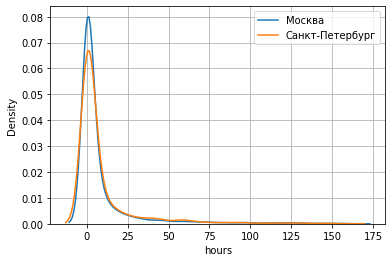

In [14]:
# Посмотрим на распределение метрики hours по городам

# Группируем данные
grouped = df.groupby("city")["hours"]

# Проходим по каждой группе и строим график плотности
for city, group in grouped:
    sns.kdeplot(group, label=city)

plt.legend()
plt.grid(True)
plt.show()

## 2. Проверка гипотезы в Python

Гипотеза звучит так: пользователи из Санкт-Петербурга проводят в среднем больше времени за чтением и прослушиванием книг в приложении, чем пользователи из Москвы. Попробуйте статистически это доказать, используя одностороннюю проверку гипотезы с двумя выборками:

- Нулевая гипотеза H₀: Средняя активность пользователей в часах в двух группах (Москва и Санкт-Петербург) не различается.

- Альтернативная гипотеза H₁: Средняя активность пользователей в Санкт-Петербурге больше, и это различие статистически значимо.

In [15]:
from scipy.stats import ttest_ind

# Разделение на группы: создаём две отдельные выборки для контрольной (A) и экспериментальной (B) групп
metric_a = df[df["city"] == "Москва"]["hours"]  # выборка целевой метрики для группы A
metric_b = df[df["city"] == "Санкт-Петербург"][
    "hours"
]  # выборка целевой метрики для группы B


# На каком уровне значимости проверяем гипотезу о равенстве выборочных средних
alpha = 0.05

# Поскольку альтернативная гипотеза о том, что выборочное среднее первой выборки (metric_a) меньше второй выборки, применяем тест Стьюдента (классический t-тест)
stat_ttest, p_value_ttest = ttest_ind(
    metric_a, metric_b, equal_var=False, alternative="less"
)

if p_value_ttest > alpha:
    print(f"p-value теста Стьюдента ={round(p_value_ttest, 2)}")
    print(
        "Не удалось отвергнуть нулевую гипотезу! Выборочные средние в группах A и B равны"
    )
    print(
        "Интерпретация: пользователи из Санкт-Петербурга в среднем не проводят больше времени за чтением и прослушиванием книг в приложении, чем пользователи из Москвы"
    )
else:
    print(f"p-value теста Стьюдента ={round(p_value_ttest, 2)}")
    print(
        "Нулевая гипотеза не находит подтверждения! Выборочные средние в группах A и B не равны, и в группе B больше"
    )
    print(
        "Интерпретация: пользователи из Санкт-Петербурга проводят в среднем больше времени за чтением и прослушиванием книг в приложении, чем пользователи из Москвы"
    )

p-value теста Стьюдента =0.09
Не удалось отвергнуть нулевую гипотезу! Выборочные средние в группах A и B равны
Интерпретация: пользователи из Санкт-Петербурга в среднем не проводят больше времени за чтением и прослушиванием книг в приложении, чем пользователи из Москвы


## 3. Аналитическая записка
По результатам анализа данных подготовьте аналитическую записку, в которой опишете:

- Выбранный тип t-теста и уровень статистической значимости: Использовал тест Стьюдента, с уровнем стат.значимости 0.05%.

- Результат теста, или p-value. p.value составил 0.09

- Вывод на основе полученного p-value, то есть интерпретацию результатов. На имеющихся данных мы не обнаружили доказательств того, что пользователи из Санкт-Петербурга проводят в приложении больше времени, чем пользователи из Москвы. Статистически их поведение не отличается

- Одну или две возможные причины, объясняющие полученные результаты.
1. Возможно дело в том, что распределение было не равномерным между городами - 70% на 30% в пользу Москвы.


----